In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("LithoAI 2.0 Research Environment")
print("Libraries imported successfully!")

LithoAI 2.0 Research Environment
Libraries imported successfully!


In [4]:
import pandas as pd

X = pd.read_csv(
    '/content/secom.data',
    sep=r'\s+',
    header=None
)

y = pd.read_csv(
    '/content/secom_labels.data',
    sep=r'\s+',
    header=None
)

print("Features:", X.shape)
print("Targets:", y.shape)

Features: (1567, 590)
Targets: (1567, 2)


In [5]:
# Display first 5 manufacturing observations
print("First 5 observations:")

print(X.iloc[:5, :10])

# Display manufacturing labels
print("\nManufacturing labels:")

print(y.head())

First 5 observations:
         0        1          2          3       4      5         6       7  \
0  3030.93  2564.00  2187.7333  1411.1265  1.3602  100.0   97.6133  0.1242   
1  3095.78  2465.14  2230.4222  1463.6606  0.8294  100.0  102.3433  0.1247   
2  2932.61  2559.94  2186.4111  1698.0172  1.5102  100.0   95.4878  0.1241   
3  2988.72  2479.90  2199.0333   909.7926  1.3204  100.0  104.2367  0.1217   
4  3032.24  2502.87  2233.3667  1326.5200  1.5334  100.0  100.3967  0.1235   

        8       9  
0  1.5005  0.0162  
1  1.4966 -0.0005  
2  1.4436  0.0041  
3  1.4882 -0.0124  
4  1.5031 -0.0031  

Manufacturing labels:
   0                    1
0 -1  19/07/2008 11:55:00
1 -1  19/07/2008 12:32:00
2  1  19/07/2008 13:17:00
3 -1  19/07/2008 14:43:00
4 -1  19/07/2008 15:22:00


In [6]:
# Convert sensor values into numerical format
X = X.apply(pd.to_numeric, errors='coerce')

# Calculate missing values
missing_values = X.isnull().sum()

# Calculate total missing values
total_missing = missing_values.sum()

# Calculate missing percentage
missing_percentage = (total_missing / X.size) * 100

print("Total sensor readings:", X.size)
print("Missing sensor readings:", total_missing)
print("Missing percentage:", round(missing_percentage, 2), "%")

Total sensor readings: 924530
Missing sensor readings: 41951
Missing percentage: 4.54 %


In [7]:
# Find sensors with highest missing values

top_missing = missing_values.sort_values(
    ascending=False
).head(10)

print(top_missing)

292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
dtype: int64


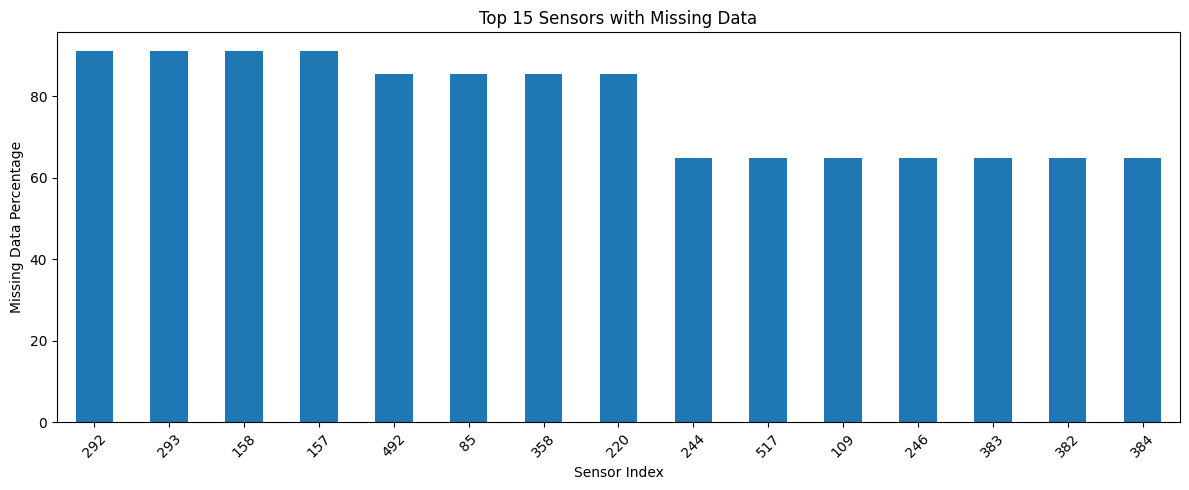

In [8]:
import matplotlib.pyplot as plt

# Calculate missing percentage for each sensor
missing_percent = (X.isnull().sum() / len(X)) * 100

# Select 15 sensors with highest missing values
top_sensors = missing_percent.sort_values(
    ascending=False
).head(15)

# Create graph
plt.figure(figsize=(12, 5))

top_sensors.plot(kind='bar')

plt.title("Top 15 Sensors with Missing Data")
plt.xlabel("Sensor Index")
plt.ylabel("Missing Data Percentage")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Preliminary Observation 1: Sensor Missingness
The SECOM dataset contains 1,567 observations and 590 sensor variables. Approximately 4.54% of all sensor readings are missing. However, the missing values are not uniformly distributed. Some sensors have more than 90% missing readings, indicating significant differences in data availability across sensors.
This observation motivates further investigation into missing-data handling techniques and their impact on prediction reliability.

Manufacturing outcome distribution:
0
-1    1463
 1     104
Name: count, dtype: int64


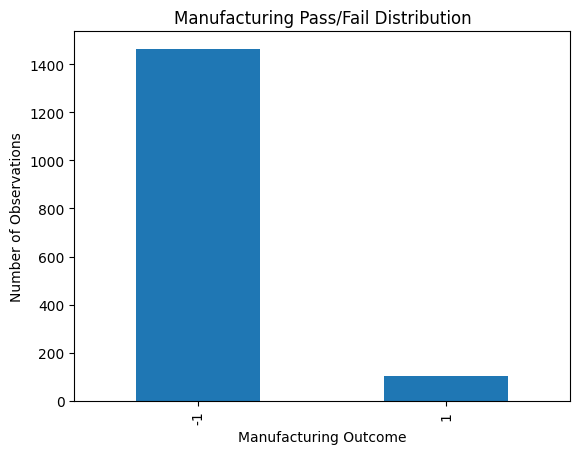

In [9]:
# Count manufacturing outcomes

print("Manufacturing outcome distribution:")

print(y[0].value_counts())

# Visualise the outcomes

y[0].value_counts().plot(
    kind='bar',
    title='Manufacturing Pass/Fail Distribution'
)

plt.xlabel("Manufacturing Outcome")
plt.ylabel("Number of Observations")
plt.show()

Preliminary Observation 2: Class Imbalance
The SECOM dataset contains 1,567 manufacturing observations, out of which 1,463 belong to the PASS category and 104 belong to the FAIL category. This indicates a significant class imbalance, with approximately 93.36% PASS and 6.64% FAIL observations.
This imbalance may affect machine learning performance and prediction reliability. Therefore, appropriate evaluation metrics beyond accuracy will be necessary.

In [10]:
# Identify sensors with constant values

unique_values = X.nunique(dropna=True)

# Find sensors having only one unique value
constant_sensors = unique_values[unique_values == 1]

# Find sensors having no valid values
empty_sensors = unique_values[unique_values == 0]

print("Total sensors:", X.shape[1])

print("Constant sensors:", len(constant_sensors))

print("Completely empty sensors:", len(empty_sensors))

print("\nConstant sensor indices:")
print(constant_sensors.index.tolist())

Total sensors: 590
Constant sensors: 116
Completely empty sensors: 0

Constant sensor indices:
[5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]


Preliminary Observation 3: Constant Sensor Detection
Analysis of the SECOM dataset identified 116 constant sensors out of 590 sensor variables. These sensors contain only one unique non-missing value and therefore provide no variation for distinguishing manufacturing outcomes. No completely empty sensors were identified.
This finding highlights the need for feature selection to reduce unnecessary dimensionality before model development.

In [11]:
from sklearn.model_selection import train_test_split

# Separate features and target
X_data = X.copy()
y_data = y.iloc[:, 0].copy()

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.2,
    random_state=42,
    stratify=y_data
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining outcome distribution:")
print(y_train.value_counts())

print("\nTesting outcome distribution:")
print(y_test.value_counts())

Training features: (1253, 590)
Testing features: (314, 590)

Training targets: (1253,)
Testing targets: (314,)

Training outcome distribution:
0
-1    1170
 1      83
Name: count, dtype: int64

Testing outcome distribution:
0
-1    293
 1     21
Name: count, dtype: int64


In [12]:
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold

# Step 1: Handle missing values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Step 2: Remove constant features
selector = VarianceThreshold(threshold=0)

X_train_clean = selector.fit_transform(X_train_imputed)
X_test_clean = selector.transform(X_test_imputed)

# Step 3: Display results
print("Original training shape:", X_train.shape)

print("Processed training shape:", X_train_clean.shape)

print("\nOriginal testing shape:", X_test.shape)

print("Processed testing shape:", X_test_clean.shape)

print("\nFeatures removed:",
      X_train.shape[1] - X_train_clean.shape[1])

print("\nRemaining features:", X_train_clean.shape[1])

print("\nMissing values after preprocessing:",
      __import__('numpy').isnan(X_train_clean).sum())

Original training shape: (1253, 590)
Processed training shape: (1253, 474)

Original testing shape: (314, 590)
Processed testing shape: (314, 474)

Features removed: 116

Remaining features: 474

Missing values after preprocessing: 0


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression model
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train_clean, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [14]:
# Predict outcomes on testing data
y_pred = model.predict(X_test_clean)

print("Predictions generated successfully!")
print("First 20 predictions:", y_pred[:20])

Predictions generated successfully!
First 20 predictions: [-1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1]


In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 84.39 %

Classification Report:
              precision    recall  f1-score   support

          -1       0.94      0.89      0.91       293
           1       0.11      0.19      0.14        21

    accuracy                           0.84       314
   macro avg       0.52      0.54      0.53       314
weighted avg       0.88      0.84      0.86       314


Confusion Matrix:
[[261  32]
 [ 17   4]]
